# M7 Лабораторийн ажил — Ноолуурын нийлүүлэлтийн гинжин хэлхээний blockchain traceability прототип

Та Монгол ноолуурын (малчин → хоршоо → боловсруулах үйлдвэр → экспортлогч) нийлүүлэлтийн
гинжин хэлхээний энгийн blockchain ledger-ийг 90 минутад Python дээр бүтээнэ.
Заавар: `Digital Tools for Sustainability_M7_Lab_Instructions_MN.docx`

  1-р даалгавар  Криптограф суурь  — SHA-256 hash, Merkle root
  2-р даалгавар  Smart contract    — бүртгэлийн дүрэм (эрх, дараалал, масс баланс)
  3-р даалгавар  Блок ба гинж      — PoW, баталгаажуулалт, хуурамч өөрчлөлт илрүүлэх
  4-р даалгавар  Digital Product Passport — Merkle proof, нүүрстөрөгчийн ул мөр
  5-р даалгавар  Эрчим хүч         — PoW vs PoA, on-chain vs off-chain хадгалалт
  6-р даалгавар  Dashboard

`# TODO` хэсгүүдийг бөглөнө. Даалгавар бүрийн төгсгөлд `CHECKPOINT` шалгалт бий.
Ажиллуулах: VS Code-д "# %%" нүд тус бүрээр (Shift+Enter) эсвэл `python m7_lab_starter.py`

**Гүйцэтгэсэн:** Батбаатар Билгүүн

### 0. Тохиргоо ба таамаглалууд (assumptions)

In [1]:
import copy
import hashlib
import json
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    HERE = Path(__file__).resolve().parent
except NameError:            # Jupyter / Colab
    HERE = Path.cwd()
DATA = next(p / "data" for p in (HERE, HERE.parent) if (p / "data" / "events.csv").exists())
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

STAGES = ["HARVEST", "COLLECT", "PROCESS", "EXPORT"]
ROLE_OF_STAGE = {"HARVEST": "HERDER", "COLLECT": "COLLECTOR", "PROCESS": "PROCESSOR", "EXPORT": "EXPORTER"}
MAX_YIELD = {"COLLECT": 1.02, "PROCESS": 0.65, "EXPORT": 1.00}   # дараагийн үе шатын хамгийн их гарц (таамаглал)
MAX_MICRON = 19.0          # ноолуурын ширхэгийн дундаж диаметрийн дээд хязгаар, мкм
BLOCK_SIZE = 8             # блок дахь үйл явдлын тоо
DIFFICULTY = 2             # PoW: hash-ийн эхэнд байх "0" тэмдэгтийн тоо (hex)
P_CPU_W = 15.0             # нэг цөмийн CPU-ийн хэрэглэх чадал, Вт (таамаглал)
EF_GRID = 0.90             # цахилгааны ялгарлын коэффициент, кгCO2/кВт.ц (таамаглал)
EF_TRUCK = 0.12            # ачааны машин, кгCO2e / (тонн·км) (таамаглал)
PROCESS_KWH_PER_KG = 4.0   # угаах, ялгах процессын цахилгаан, кВт.ц / кг түүхий ноолуур (таамаглал)


def canonical(obj):
    """Hash тооцоолохын өмнө JSON-ийг нэг утгатай (canonical) болгоно — түлхүүр эрэмбэлсэн, хоосон зайгүй."""
    return json.dumps(obj, sort_keys=True, separators=(",", ":"), ensure_ascii=False).encode("utf-8")


def event_to_record(row):
    """CSV мөрийг ledger-д хадгалах тогтмол бүтэцтэй dict болгоно."""
    micron = row["fiber_micron"]
    return {"event_id": str(row["event_id"]), "batch_id": str(row["batch_id"]), "stage": str(row["stage"]),
            "actor_id": str(row["actor_id"]), "timestamp": str(row["timestamp"]), "aimag": str(row["aimag"]),
            "qty_kg": round(float(row["qty_kg"]), 1),
            "fiber_micron": None if pd.isna(micron) else round(float(micron), 2),
            "transport_km": int(row["transport_km"])}


actors = pd.read_csv(DATA / "actors.csv")
events = pd.read_csv(DATA / "events.csv")
records = [event_to_record(r) for _, r in events.iterrows()]
print(f"{len(actors)} оролцогч, {len(records)} үйл явдал, {events.batch_id.nunique()} багц")

34 оролцогч, 193 үйл явдал, 48 багц


### 1-р даалгавар — Криптограф суурь: hash ба Merkle root

In [2]:
def sha256_hex(obj):
    # TODO 1.1 — canonical JSON байтуудын SHA-256 hex
    return hashlib.sha256(canonical(obj)).hexdigest()


def merkle_root(hashes):
    """Хос хосоор нь (зүүн+баруун hex мөрийг залгаж) hash хийнэ; сондгой бол сүүлийнхийг давхарлана."""
    if not hashes:
        return sha256_hex("")
    level = list(hashes)
    while len(level) > 1:
        # TODO 1.2 — сондгой бол сүүлийнхийг давхарлаж, хос бүрийг нэгтгэнэ
        if len(level) % 2:
            level.append(level[-1])
        level = [hashlib.sha256((level[i] + level[i + 1]).encode()).hexdigest()
                 for i in range(0, len(level), 2)]
    return level[0]


demo = {"batch_id": "MNC-DEMO", "qty_kg": 120.5, "stage": "HARVEST"}
print("sha256(demo) =", sha256_hex(demo))
changed = dict(demo, qty_kg=120.6)
print("0.1 кг өөрчлөхөд  =", sha256_hex(changed), "(avalanche effect)")

# CHECKPOINT 1
assert sha256_hex(demo) == hashlib.sha256(b'{"batch_id":"MNC-DEMO","qty_kg":120.5,"stage":"HARVEST"}').hexdigest()
assert merkle_root(["a" * 64]) == "a" * 64
assert merkle_root(["a" * 64, "b" * 64, "c" * 64]) == merkle_root(["a" * 64, "b" * 64, "c" * 64, "c" * 64])
print("✔ CHECKPOINT 1 давлаа")

sha256(demo) = 0ee15c727ab881ea4dd1c5fc4f1f7ef2795cc9604c1c958a9d7a64cf93918f28
0.1 кг өөрчлөхөд  = 43bfb6686229303f65e1c7d161b001e1b499cdc8a75053ab6b2356c9499f9571 (avalanche effect)
✔ CHECKPOINT 1 давлаа


### 2-р даалгавар — Smart contract: бүртгэлийн дүрэм (validation rules)

In [3]:
class TraceabilityContract:
    """Ухаалаг гэрээний энгийн загвар: үйл явдлыг ledger-д бичихээс өмнө дүрмээр шалгана."""

    def __init__(self, actors):
        self.role = dict(zip(actors.actor_id, actors.role))
        self.seen_ids = set()
        self.state = {}               # batch_id -> хамгийн сүүлд зөвшөөрөгдсөн үйл явдал

    def check(self, r):
        prev = self.state.get(r["batch_id"])
        if r["event_id"] in self.seen_ids:
            return "duplicate"                                           # давхар илгээлт (replay)
        if self.role.get(r["actor_id"]) != ROLE_OF_STAGE[r["stage"]]:
            return "unauthorized"                                        # эрхгүй оролцогч
        expected = STAGES[0] if prev is None else (
            STAGES[STAGES.index(prev["stage"]) + 1] if prev["stage"] != "EXPORT" else None)
        # TODO 2.1 — Дараалал
        if r["stage"] != expected:
            return "order"
        # TODO 2.2 — Ширхэг
        if r["stage"] == "HARVEST" and (r["fiber_micron"] is None or r["fiber_micron"] > MAX_MICRON):
            return "fiber"
        # TODO 2.3 — Масс баланс
        if prev is not None and r["qty_kg"] > prev["qty_kg"] * MAX_YIELD[r["stage"]]:
            return "mass_balance"
        return None

    def submit(self, r):
        reason = self.check(r)
        if reason is None:
            self.seen_ids.add(r["event_id"])
            self.state[r["batch_id"]] = r
        return reason

    def filter(self, records):
        accepted, rejected = [], []
        for r in records:
            reason = self.submit(r)
            if reason is None:
                accepted.append(r)
            else:
                rejected.append({**r, "reason": reason})
        return accepted, pd.DataFrame(rejected)


contract = TraceabilityContract(actors)
accepted, rejected = contract.filter(records)
reasons = rejected["reason"].value_counts()
print(f"Зөвшөөрсөн: {len(accepted)},  татгалзсан: {len(rejected)}")
print(reasons.to_string())

# CHECKPOINT 2
assert len(accepted) + len(rejected) == len(records)
assert set(reasons.index) == {"duplicate", "unauthorized", "order", "fiber", "mass_balance"}, "5 төрлийн дүрэм бүгд ажиллах ёстой"
print("✔ CHECKPOINT 2 давлаа")

Зөвшөөрсөн: 172,  татгалзсан: 21
reason
order           13
mass_balance     3
fiber            2
unauthorized     2
duplicate        1
✔ CHECKPOINT 2 давлаа


### 3-р даалгавар — Блок, гинж, баталгаажуулалт ба хуурамч өөрчлөлт илрүүлэх

In [4]:
def mine(header, difficulty):
    """Proof-of-Work: nonce = 0, 1, 2, ... гэж нэмэгдүүлж hash "0"*difficulty-ээр эхлэхийг хайна."""
    # TODO 3.1 — nonce = 0, 1, 2, ... hash "0"*difficulty-ээр эхлэх хүртэл
    target = "0" * difficulty
    nonce = 0
    while True:
        header["nonce"] = nonce
        h = sha256_hex(header)
        if h.startswith(target):
            return h, nonce + 1
        nonce += 1


def build_chain(records, block_size=BLOCK_SIZE, difficulty=DIFFICULTY):
    genesis = {"index": 0, "timestamp": "2026-03-01T00:00:00", "prev_hash": "0" * 64,
               "merkle_root": merkle_root([]), "difficulty": difficulty, "nonce": 0}
    chain = [{"header": genesis, "hash": mine(genesis, difficulty)[0], "events": []}]
    for i in range(0, len(records), block_size):
        evs = records[i:i + block_size]
        header = {"index": len(chain), "timestamp": evs[-1]["timestamp"], "prev_hash": chain[-1]["hash"],
                  "merkle_root": merkle_root([sha256_hex(e) for e in evs]), "difficulty": difficulty, "nonce": 0}
        chain.append({"header": header, "hash": mine(header, difficulty)[0], "events": evs})
    return chain


def verify_chain(chain):
    """Асуудал бүрийг (блокийн дугаар, тайлбар) хэлбэрээр буцаана. Хоосон жагсаалт = гинж бүрэн бүтэн."""
    problems = []
    for i, blk in enumerate(chain):
        h = blk["header"]
        if sha256_hex(h) != blk["hash"]:
            problems.append((i, "block hash буруу"))
        if not blk["hash"].startswith("0" * h["difficulty"]):
            problems.append((i, "PoW хангаагүй"))
        # TODO 3.2 — (а) merkle_root, (б) prev_hash шалгалт
        if merkle_root([sha256_hex(e) for e in blk["events"]]) != h["merkle_root"]:
            problems.append((i, "merkle_root таарахгүй (үйл явдал өөрчлөгдсөн)"))
        if i > 0 and h["prev_hash"] != chain[i - 1]["hash"]:
            problems.append((i, "prev_hash таарахгүй (өмнөх блок өөрчлөгдсөн)"))
    return problems


t0 = time.perf_counter()
chain = build_chain(accepted)
print(f"Өөрийн гинж: {len(chain)} блок, {time.perf_counter() - t0:.2f} сек, асуудал: {verify_chain(chain)}")

# 3a. Туршилт: өөрийн гинжинд нэг үйл явдлыг өөрчилбөл?
tampered = copy.deepcopy(chain)
tampered[3]["events"][0]["qty_kg"] += 10
print("Туршилт (блок 3-т +10 кг):", verify_chain(tampered))

# 3b. Мөрдөгчийн даалгавар: хоршооноос ирсэн ledger_export.json-г шалгах
with open(DATA / "ledger_export.json", encoding="utf-8") as f:
    export = json.load(f)
export_problems = verify_chain(export)
print("ledger_export.json:", export_problems)
diff_blocks = [i for i, (a, b) in enumerate(zip(chain, export)) if a["hash"] != b["hash"]]
print("Өөрийн гинжтэй харьцуулахад hash нь өөр блокууд:", diff_blocks)
for i in sorted({b for b, _ in export_problems} | set(diff_blocks)):
    for e_own, e_exp in zip(chain[i]["events"], export[i]["events"]):
        if e_own != e_exp:
            changed_fields = {k: (e_own[k], e_exp[k]) for k in e_own if e_own[k] != e_exp[k]}
            print(f"  блок {i}, {e_own['event_id']}: {changed_fields}")

# CHECKPOINT 3
assert verify_chain(chain) == [], "Өөрийн гинж алдаагүй байх ёстой"
assert {b for b, _ in export_problems} == {5, 13}
print("✔ CHECKPOINT 3 давлаа")

Өөрийн гинж: 23 блок, 0.02 сек, асуудал: []
Туршилт (блок 3-т +10 кг): [(3, 'merkle_root таарахгүй (үйл явдал өөрчлөгдсөн)')]
ledger_export.json: [(5, 'merkle_root таарахгүй (үйл явдал өөрчлөгдсөн)'), (13, 'prev_hash таарахгүй (өмнөх блок өөрчлөгдсөн)')]
Өөрийн гинжтэй харьцуулахад hash нь өөр блокууд: [12]
  блок 5, EV-0037: {'qty_kg': (80.4, 105.4)}
  блок 12, EV-0096: {'aimag': ('Баянхонгор', 'Сүхбаатар')}
✔ CHECKPOINT 3 давлаа


### 4-р даалгавар — Дижитал бүтээгдэхүүний паспорт (DPP) ба Merkle proof

In [5]:
def merkle_proof(hashes, idx):
    """idx-р навчны inclusion proof: [(хөршийн hash, хөрш нь баруун талд эсэх), ...]"""
    proof, level = [], list(hashes)
    while len(level) > 1:
        if len(level) % 2:
            level.append(level[-1])
        sib = idx ^ 1
        proof.append((level[sib], sib > idx))
        level = [hashlib.sha256((level[i] + level[i + 1]).encode()).hexdigest() for i in range(0, len(level), 2)]
        idx //= 2
    return proof


def verify_proof(leaf_hash, proof, root):
    h = leaf_hash
    # TODO 4.1 — proof-ийн дагуу дээш hash хийж root-той харьцуулна
    for sib, sib_is_right in proof:
        pair = h + sib if sib_is_right else sib + h
        h = hashlib.sha256(pair.encode()).hexdigest()
    return h == root


def build_dpp(chain, batch_id, actors):
    name = dict(zip(actors.actor_id, actors.name))
    cert = dict(zip(actors.actor_id, actors.certified))
    steps, co2 = [], 0.0
    for blk in chain:
        hashes = [sha256_hex(e) for e in blk["events"]]
        for j, e in enumerate(blk["events"]):
            if e["batch_id"] != batch_id:
                continue
            proof = merkle_proof(hashes, j)
            steps.append({"stage": e["stage"], "actor": name[e["actor_id"]], "aimag": e["aimag"],
                          "timestamp": e["timestamp"], "qty_kg": e["qty_kg"], "block": blk["header"]["index"],
                          "event_hash": hashes[j], "merkle_root": blk["header"]["merkle_root"],
                          "proof_ok": verify_proof(hashes[j], proof, blk["header"]["merkle_root"])})
            co2 += e["qty_kg"] / 1000 * e["transport_km"] * EF_TRUCK
            if e["stage"] == "PROCESS":
                co2 += steps[-2]["qty_kg"] * PROCESS_KWH_PER_KG * EF_GRID if len(steps) >= 2 else 0
    final_kg = steps[-1]["qty_kg"]
    harvest = next(s for s in steps if s["stage"] == "HARVEST")
    herder = next(e["actor_id"] for b in chain for e in b["events"] if e["batch_id"] == batch_id and e["stage"] == "HARVEST")
    return {"dpp_version": "0.1-lab", "product": "Ялгасан ноолуур (dehaired cashmere)", "batch_id": batch_id,
            "origin": {"aimag": harvest["aimag"], "herder_certified": bool(cert[herder])},
            "final_qty_kg": final_kg, "carbon_kgCO2e_per_kg": round(co2 / final_kg, 2),
            "chain_of_custody": steps, "all_proofs_valid": all(s["proof_ok"] for s in steps)}


complete = [b for b, g in pd.DataFrame(accepted).groupby("batch_id") if set(g.stage) == set(STAGES)]
dpp = build_dpp(chain, complete[0], actors)
with open(OUT / f"dpp_{complete[0]}.json", "w", encoding="utf-8") as f:
    json.dump(dpp, f, ensure_ascii=False, indent=2)
print(f"Бүрэн замтай багц: {len(complete)}. DPP: {complete[0]}, "
      f"{dpp['carbon_kgCO2e_per_kg']} кгCO2e/кг, proofs={dpp['all_proofs_valid']}")
dpp_all = pd.DataFrame([{k: build_dpp(chain, b, actors)[k] for k in ("batch_id", "final_qty_kg", "carbon_kgCO2e_per_kg")}
                        for b in complete])

# CHECKPOINT 4
step0 = dpp["chain_of_custody"][0]
blk = chain[step0["block"]]
hashes = [sha256_hex(e) for e in blk["events"]]
j = hashes.index(step0["event_hash"])
assert dpp["all_proofs_valid"] and len(dpp["chain_of_custody"]) == 4
assert not verify_proof(sha256_hex({**blk["events"][j], "qty_kg": 999.0}), merkle_proof(hashes, j), blk["header"]["merkle_root"])
print("✔ CHECKPOINT 4 давлаа")

Бүрэн замтай багц: 39. DPP: MNC-2026-001, 7.34 кгCO2e/кг, proofs=True
✔ CHECKPOINT 4 давлаа


### 5-р даалгавар — Зөвшилцлийн механизмын эрчим хүч ба хадгалалтын ул мөр

In [6]:
def measure_hashrate(seconds=1.0):
    h = {"index": 1, "prev_hash": "0" * 64, "merkle_root": "f" * 64, "nonce": 0}
    n, t = 0, time.perf_counter()
    while time.perf_counter() - t < seconds:
        h["nonce"] = n
        sha256_hex(h)
        n += 1
    return n / (time.perf_counter() - t)


hashrate = measure_hashrate()
j_per_hash = P_CPU_W / hashrate
rows = []
for d in range(1, 7):
    if d <= 4:                                   # хэмжсэн: 5 блок дээр бодитоор mine хийнэ
        attempts = float(np.mean([mine(copy.deepcopy(chain[k]["header"]), d)[1] for k in range(1, 6)]))
        source = "хэмжсэн"
    else:                                        # онолын: дунджаар 16^d оролдлого (удаан тул хэмжихгүй)
        attempts, source = float(16 ** d), "онолын"
    rows.append({"consensus": f"PoW d={d}", "difficulty": d, "source": source,
                 "attempts_mean": attempts, "expected_16^d": 16 ** d})
pow_df = pd.DataFrame(rows)
pow_df.loc[len(pow_df)] = {"consensus": "PoA", "difficulty": 0, "source": "хэмжсэн",
                           "attempts_mean": 1.0, "expected_16^d": 1}
MINERS, BLOCKS_PER_YEAR = 10, 52_560          # 10 уурхайчин, 10 минут тутам нэг блок (таамаглал)
# TODO 5.1 — J_per_block = attempts_mean × j_per_hash.
#            kWh_per_year = (оролцогчийн тоо) × J_per_block × BLOCKS_PER_YEAR / 3.6e6,
#            PoW-д бүх MINERS өрсөлдөнө, PoA-д 1 validator блок үүсгэнэ (np.where(pow_df.difficulty > 0, MINERS, 1)).
pow_df["J_per_block"] = pow_df["attempts_mean"] * j_per_hash
participants = np.where(pow_df.difficulty > 0, MINERS, 1)
pow_df["kWh_per_year"] = participants * pow_df["J_per_block"] * BLOCKS_PER_YEAR / 3.6e6
pow_df["kgCO2_per_year"] = pow_df["kWh_per_year"] * EF_GRID
print(f"Hash rate ≈ {hashrate:,.0f} hash/сек  →  {j_per_hash * 1e6:.1f} мкДж/hash")
print(pow_df.round(4).to_string(index=False))

# TODO 5.2 — onchain_full: бүх зөвшөөрсөн үйл явдлын canonical(e) байтын нийлбэр;
#            onchain_hash: зөвхөн SHA-256 anchor (үйл явдал бүрт 32 байт) хадгалбал хэдэн байт вэ?
onchain_full = sum(len(canonical(e)) for e in accepted)
onchain_hash = 32 * len(accepted)
print(f"Бүх өгөгдөл on-chain: {onchain_full:,} байт; зөвхөн hash on-chain: {onchain_hash:,} байт "
      f"({onchain_full / onchain_hash:.1f}× бага)")

# CHECKPOINT 5
assert pow_df.attempts_mean.iloc[3] / pow_df.attempts_mean.iloc[0] > 300   # хүлээгдэх харьцаа 4096
assert pow_df["kWh_per_year"].notna().all() and onchain_full > onchain_hash > 1, "TODO 5.1, 5.2"
print("✔ CHECKPOINT 5 давлаа")

Hash rate ≈ 334,229 hash/сек  →  44.9 мкДж/hash
consensus  difficulty  source  attempts_mean  expected_16^d  J_per_block  kWh_per_year  kgCO2_per_year
  PoW d=1           1 хэмжсэн           14.6             16       0.0007        0.0001          0.0001
  PoW d=2           2 хэмжсэн          444.0            256       0.0199        0.0029          0.0026
  PoW d=3           3 хэмжсэн         5744.8           4096       0.2578        0.0376          0.0339
  PoW d=4           4 хэмжсэн        27913.2          65536       1.2527        0.1829          0.1646
  PoW d=5           5  онолын      1048576.0        1048576      47.0595        6.8707          6.1836
  PoW d=6           6  онолын     16777216.0       16777216     752.9526      109.9311         98.9380
      PoA           0 хэмжсэн            1.0              1       0.0000        0.0000          0.0000
Бүх өгөгдөл on-chain: 34,905 байт; зөвхөн hash on-chain: 5,504 байт (6.3× бага)
✔ CHECKPOINT 5 давлаа


### 6-р даалгавар — Dashboard

Хадгалсан: output/dashboard.png


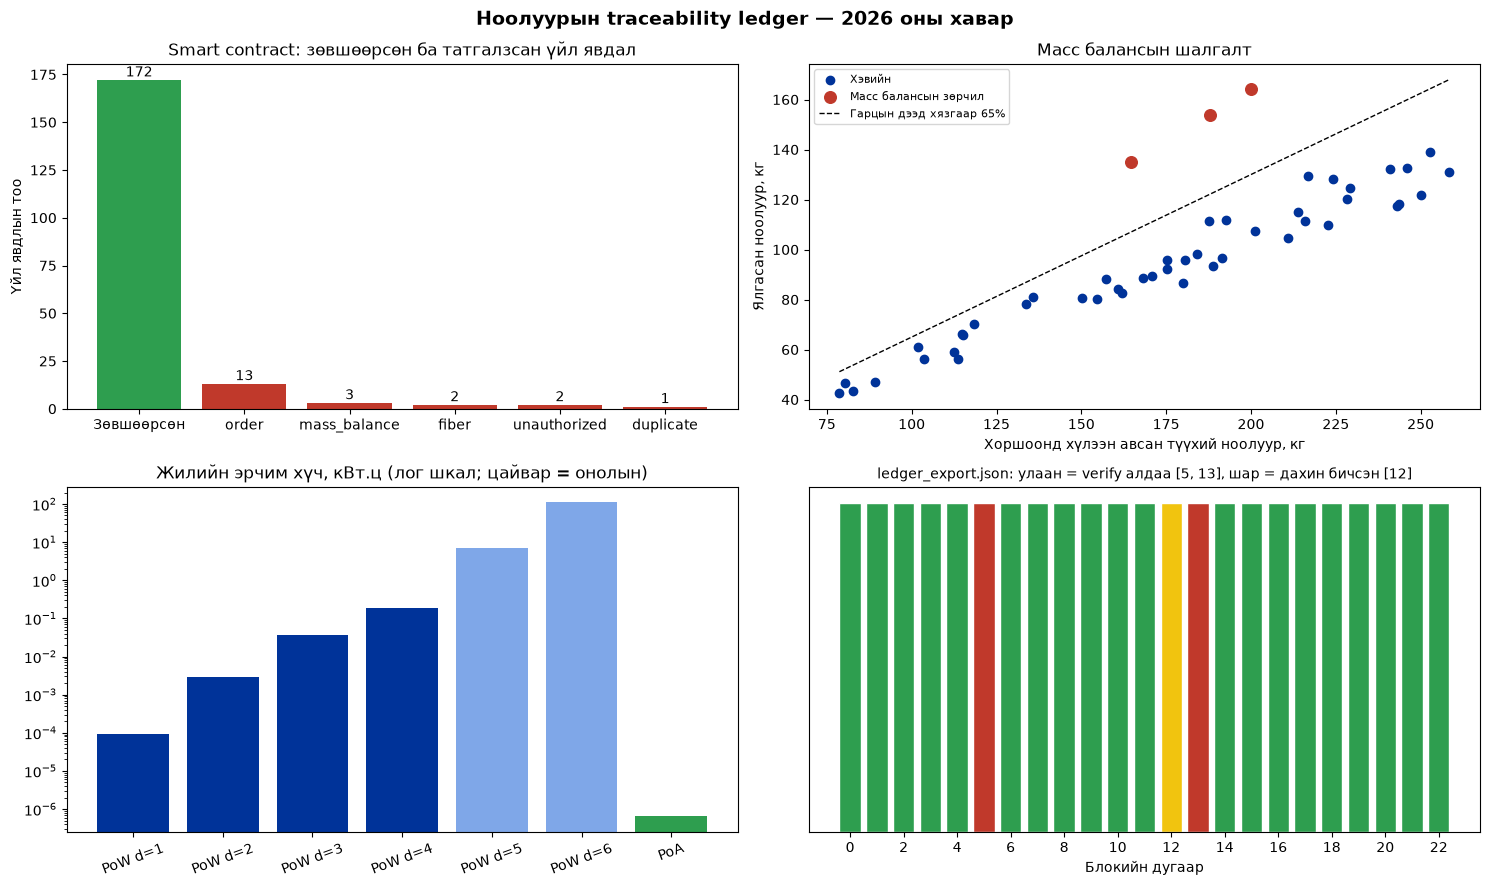

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
fig.suptitle("Ноолуурын traceability ledger — 2026 оны хавар", fontsize=14, fontweight="bold")

a = ax[0, 0]
lab = ["Зөвшөөрсөн"] + list(reasons.index)
val = [len(accepted)] + list(reasons.values)
a.bar(lab, val, color=["#2E9E4F"] + ["#C0392B"] * len(reasons))
for i, v in enumerate(val):
    a.text(i, v + 2, str(v), ha="center")
a.set_title("Smart contract: зөвшөөрсөн ба татгалзсан үйл явдал"); a.set_ylabel("Үйл явдлын тоо")

a = ax[0, 1]
ev = pd.DataFrame(records)
col = ev[ev.stage == "COLLECT"].drop_duplicates("batch_id").set_index("batch_id")["qty_kg"]
prc = ev[ev.stage == "PROCESS"].set_index("batch_id")["qty_kg"]
mb = pd.concat([col, prc], axis=1, keys=["collect", "process"]).dropna()
bad = mb["process"] > mb["collect"] * MAX_YIELD["PROCESS"]
a.scatter(mb.collect[~bad], mb.process[~bad], c="#003399", label="Хэвийн")
a.scatter(mb.collect[bad], mb.process[bad], c="#C0392B", s=70, label="Масс балансын зөрчил")
xs = np.linspace(mb.collect.min(), mb.collect.max(), 10)
a.plot(xs, xs * MAX_YIELD["PROCESS"], "k--", lw=1, label="Гарцын дээд хязгаар 65%")
a.set_xlabel("Хоршоонд хүлээн авсан түүхий ноолуур, кг"); a.set_ylabel("Ялгасан ноолуур, кг")
a.set_title("Масс балансын шалгалт"); a.legend(fontsize=8)

a = ax[1, 0]
a.bar(pow_df.consensus, pow_df.kWh_per_year, color=["#003399"] * 4 + ["#7FA7E8"] * 2 + ["#2E9E4F"])
a.set_yscale("log")
a.set_title("Жилийн эрчим хүч, кВт.ц (лог шкал; цайвар = онолын)")
a.tick_params(axis="x", rotation=20)

a = ax[1, 1]
bad_blocks = {b for b, _ in export_problems}
# TODO 6.1 — экспортын блок бүр: улаан = verify алдаа, шар = дахин бичсэн, ногоон = хэвийн
rewritten = set(diff_blocks) - bad_blocks
colors = ["#C0392B" if i in bad_blocks else "#F1C40F" if i in rewritten else "#2E9E4F"
          for i in range(len(export))]
a.bar(range(len(export)), [1] * len(export), color=colors, edgecolor="white")
a.set_yticks([]); a.set_xlabel("Блокийн дугаар")
a.set_xticks(range(0, len(export), 2))
a.set_title(f"ledger_export.json: улаан = verify алдаа {sorted(bad_blocks)}, шар = дахин бичсэн {sorted(rewritten)}", fontsize=10)

fig.tight_layout()
fig.savefig(OUT / "dashboard.png", dpi=150)
pow_df.to_csv(OUT / "consensus_energy.csv", index=False, encoding="utf-8-sig")
rejected.to_csv(OUT / "rejected_events.csv", index=False, encoding="utf-8-sig")
print("Хадгалсан:", OUT / "dashboard.png")